In [6]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [7]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [8]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052



FOLD 1/5


100%|██████████| 40/40 [00:11<00:00,  3.45it/s]


Epoch [1/50] Train Loss: 0.6593 (CE: 0.8103, Dice: 0.5083), Train Acc: 0.4965 | Val Loss: 0.6723 (CE: 0.6942, Dice: 0.6504), Val Acc: 0.3312
  -> Saving best model (Val Accuracy: 0.3312)


100%|██████████| 40/40 [00:11<00:00,  3.63it/s]


Epoch [2/50] Train Loss: 0.5908 (CE: 0.6882, Dice: 0.4935), Train Acc: 0.5551 | Val Loss: 0.6790 (CE: 0.7071, Dice: 0.6509), Val Acc: 0.6312
  -> Saving best model (Val Accuracy: 0.6312)


...

Epoch [25/50] Train Loss: 0.4275 (CE: 0.5184, Dice: 0.3365), Train Acc: 0.7145 | Val Loss: 0.5883 (CE: 0.5633, Dice: 0.6132), Val Acc: 0.5906
  -> No improvement for 6/8 epochs


100%|██████████| 40/40 [00:11<00:00,  3.60it/s]


Epoch [26/50] Train Loss: 0.4116 (CE: 0.4967, Dice: 0.3265), Train Acc: 0.7242 | Val Loss: 0.5518 (CE: 0.5021, Dice: 0.6014), Val Acc: 0.6578
  -> No improvement for 7/8 epochs


100%|██████████| 40/40 [00:11<00:00,  3.55it/s]


Epoch [27/50] Train Loss: 0.4078 (CE: 0.4892, Dice: 0.3265), Train Acc: 0.7285 | Val Loss: 0.6063 (CE: 0.6048, Dice: 0.6078), Val Acc: 0.6234
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 27. Best Val Accuracy: 0.6875

Fold 5 Best Validation Accuracy: 0.6875

5-FOLD CROSS-VALIDATION RESULTS
Fold 1 Validation Accuracy: 0.6781
Fold 2 Validation Accuracy: 0.6438
Fold 3 Validation Accuracy: 0.7047
Fold 4 Validation Accuracy: 0.7344
Fold 5 Validation Accuracy: 0.6875

Mean CV Accuracy: 0.6897
CV Standard Deviation: 0.0299
Best CV Accuracy: 0.7344

Final Test Loss: 0.5178 (CE: 0.4402, Dice: 0.5955), Final Test Accuracy: 0.8658

Test Precision (weighted): 0.8644
Test Recall (weighted):    0.8658
Test F1-score (weighted):  0.8595

Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.87      0.96      0.91      1052
  Appears normal       0.85      0.64      0.73       416

        accuracy                           0.87  

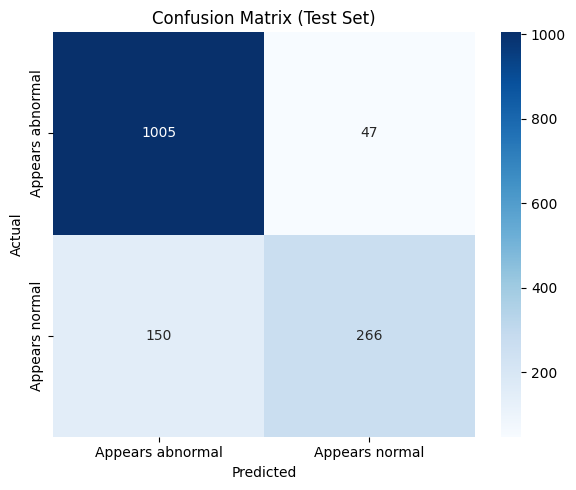

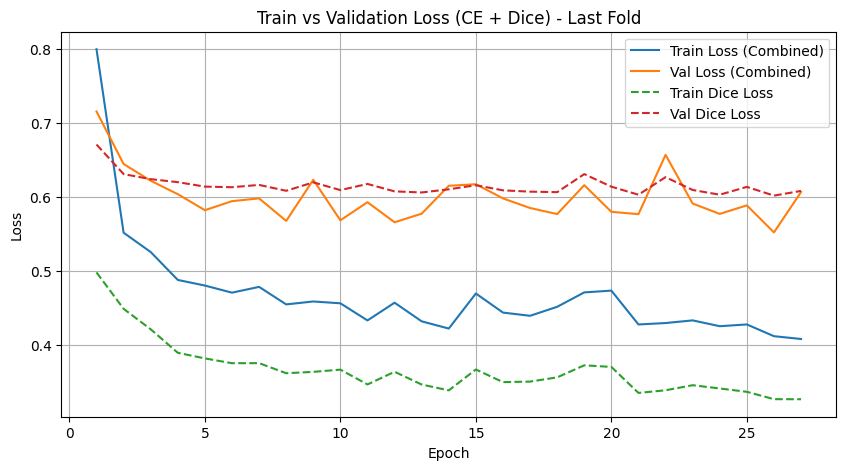

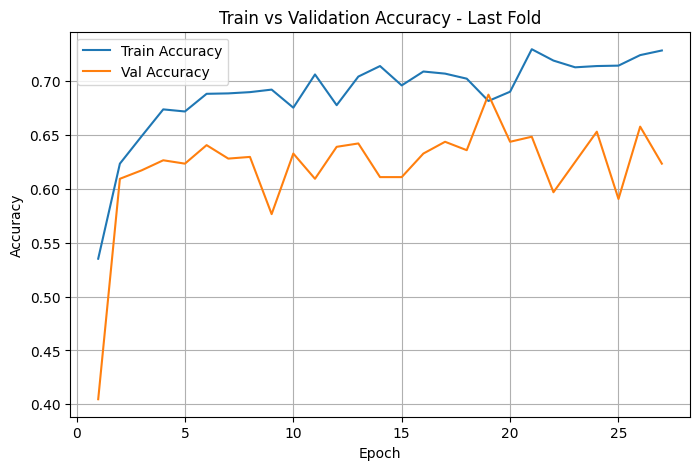

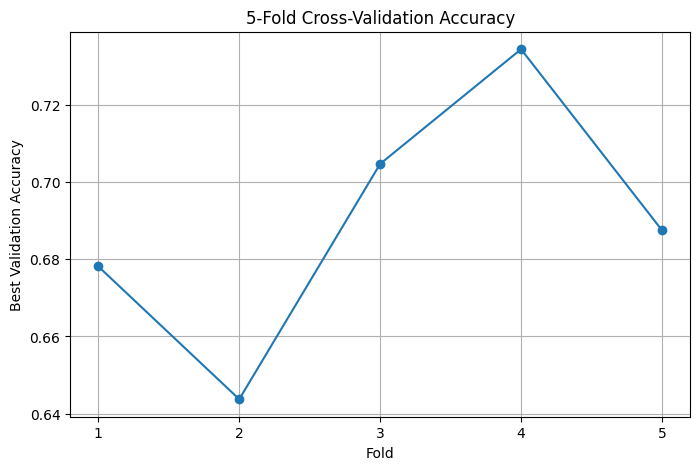


Summary:
Mean 5-Fold CV Accuracy: 0.6897
CV Standard Deviation: 0.0299
Best CV Accuracy: 0.7344
Final Test Accuracy (evaluated once, held-out set): 0.8658
Final Test Precision: 0.8644, Recall: 0.8658, F1: 0.8595
Final Test Dice Loss: 0.5955


In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from torchvision import datasets, transforms
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import KFold
import seaborn as sns

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)

# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

num_classes = len(train_dataset.classes)

# Test loader remains untouched
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)


# ============================================================
# AlexNet architecture (224x224 input)
# ============================================================

class AlexNet(nn.Module):
    def __init__(self, num_classes):
        super(AlexNet, self).__init__()

        self.conv1 = nn.Conv2d(3, 96, kernel_size=11, stride=4)
        self.conv2 = nn.Conv2d(96, 256, kernel_size=5, padding=2)
        self.conv3 = nn.Conv2d(256, 384, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(384, 384, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(384, 256, kernel_size=3, padding=1)

        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2)
        self.dropout = nn.Dropout(0.5)

        self._to_linear = None
        self.convs(torch.randn(1, 3, 224, 224))

        self.fc1 = nn.Linear(self._to_linear, 4096)
        self.fc2 = nn.Linear(4096, 4096)
        self.fc3 = nn.Linear(4096, num_classes)

    def convs(self, x):
        x = F.relu(self.conv1(x))
        x = self.maxpool(x)

        x = F.relu(self.conv2(x))
        x = self.maxpool(x)

        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = F.relu(self.conv5(x))

        x = self.maxpool(x)

        if self._to_linear is None:
            self._to_linear = x.view(x.size(0), -1).shape[1]

        return x

    def forward(self, x):
        x = self.convs(x)
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):
    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = probs.sum(dim=0) + targets_one_hot.sum(dim=0)

        dice_score = (
            (2. * intersection + self.smooth)
            / (union + self.smooth)
        )

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):
    def __init__(self, num_classes, ce_weight=0.5, dice_weight=0.5):
        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        ce = self.ce_loss(logits, targets)

        dice = self.dice_loss(logits, targets)

        total = (
            self.ce_weight * ce
            + self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# Evaluation function
# ============================================================

def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images, labels = images.to(device), labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(outputs, labels)

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images, labels = images.to(device), labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

overall_best_accuracy = 0.0

best_model_path = "AlexNet_best.pkl"

patience = 8

max_epochs = 50

fold_accuracies = []


# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

for fold, (train_indices, val_indices) in enumerate(
        kfold.split(train_dataset), 1):

    print("\n" + "=" * 60)
    print(f"FOLD {fold}/5")
    print("=" * 60)

    # --------------------------------------------------------
    # Train / validation subsets for this fold
    # --------------------------------------------------------

    train_subset = Subset(
        train_dataset,
        train_indices
    )

    val_subset = Subset(
        train_dataset,
        val_indices
    )


    # --------------------------------------------------------
    # Count samples per class for THIS training fold
    # --------------------------------------------------------

    train_targets = [
        train_dataset.targets[i]
        for i in train_indices
    ]

    class_counts = np.bincount(train_targets)

    class_weights = 1. / class_counts

    sample_weights = [
        class_weights[label]
        for label in train_targets
    ]

    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(train_subset),
        replacement=True
    )


    # --------------------------------------------------------
    # DataLoaders
    # --------------------------------------------------------

    train_loader = DataLoader(
        train_subset,
        batch_size=64,
        sampler=sampler
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=64,
        shuffle=False
    )


    # --------------------------------------------------------
    # IMPORTANT: Fresh model for every fold
    # --------------------------------------------------------

    alexnet = AlexNet(num_classes).to(device)

    optimizer = optim.Adam(
        alexnet.parameters(),
        lr=0.001
    )


    # --------------------------------------------------------
    # Early stopping setup for this fold
    # --------------------------------------------------------

    best_accuracy = 0.0

    epochs_no_improve = 0


    # --------------------------------------------------------
    # Graph data
    # --------------------------------------------------------

    train_losses, train_accs = [], []
    val_losses, val_accs = [], []

    train_ce_losses, train_dice_losses = [], []
    val_ce_losses, val_dice_losses = [], []


    # ========================================================
    # Training
    # ========================================================

    for epoch in range(max_epochs):

        alexnet.train()

        running_loss = 0.0
        running_ce = 0.0
        running_dice = 0.0

        correct_train = 0
        total_train = 0


        for images, labels in tqdm(train_loader):

            images, labels = images.to(device), labels.to(device)

            outputs = alexnet(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            optimizer.zero_grad()

            loss.backward()

            optimizer.step()


            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()


            _, predicted = torch.max(
                outputs,
                1
            )

            total_train += labels.size(0)

            correct_train += (
                predicted == labels
            ).sum().item()


        train_accuracy = (
            correct_train / total_train
        )

        n_batches = len(train_loader)

        train_loss = running_loss / n_batches
        train_ce = running_ce / n_batches
        train_dice = running_dice / n_batches


        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
            alexnet,
            val_loader
        )


        # ----------------------------------------------------
        # Save graph data
        # ----------------------------------------------------

        train_losses.append(train_loss)
        train_accs.append(train_accuracy)

        val_losses.append(val_loss)
        val_accs.append(val_accuracy)

        train_ce_losses.append(train_ce)
        train_dice_losses.append(train_dice)

        val_ce_losses.append(val_ce)
        val_dice_losses.append(val_dice)


        print(
            f'Epoch [{epoch+1}/{max_epochs}] '
            f'Train Loss: {train_loss:.4f} '
            f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
            f'Train Acc: {train_accuracy:.4f} | '
            f'Val Loss: {val_loss:.4f} '
            f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
            f'Val Acc: {val_accuracy:.4f}'
        )


        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if val_accuracy > best_accuracy:

            best_accuracy = val_accuracy

            epochs_no_improve = 0

            print(
                f'  -> Saving best model '
                f'(Val Accuracy: {best_accuracy:.4f})'
            )

            # Save best model from this fold
            torch.save(
                alexnet.state_dict(),
                f"AlexNet_fold_{fold}_best.pkl"
            )


            # Save overall best model
            if val_accuracy > overall_best_accuracy:

                overall_best_accuracy = val_accuracy

                torch.save(
                    alexnet.state_dict(),
                    best_model_path
                )

        else:

            epochs_no_improve += 1

            print(
                f'  -> No improvement for '
                f'{epochs_no_improve}/{patience} epochs'
            )


        if epochs_no_improve >= patience:

            print(
                f'\nEarly stopping triggered at '
                f'epoch {epoch+1}. '
                f'Best Val Accuracy: {best_accuracy:.4f}'
            )

            break


    # --------------------------------------------------------
    # Store fold result
    # --------------------------------------------------------

    fold_accuracies.append(best_accuracy)

    print(
        f'\nFold {fold} Best Validation Accuracy: '
        f'{best_accuracy:.4f}'
    )


# ============================================================
# 5-FOLD RESULTS
# ============================================================

print("\n" + "=" * 60)
print("5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 60)

for i, accuracy in enumerate(fold_accuracies, 1):

    print(
        f"Fold {i} Validation Accuracy: "
        f"{accuracy:.4f}"
    )


mean_cv_accuracy = np.mean(fold_accuracies)

std_cv_accuracy = np.std(fold_accuracies)

print(
    f"\nMean CV Accuracy: "
    f"{mean_cv_accuracy:.4f}"
)

print(
    f"CV Standard Deviation: "
    f"{std_cv_accuracy:.4f}"
)

print(
    f"Best CV Accuracy: "
    f"{overall_best_accuracy:.4f}"
)


# ============================================================
# Load the best model from the 5 folds
# ============================================================

best_alexnet_model = AlexNet(num_classes).to(device)

best_alexnet_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)


# ============================================================
# Test set - evaluated ONCE
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_alexnet_model,
    test_loader
)

print(
    f'\nFinal Test Loss: {test_loss:.4f} '
    f'(CE: {test_ce:.4f}, Dice: {test_dice:.4f}), '
    f'Final Test Accuracy: {test_accuracy:.4f}'
)


# ============================================================
# Precision, Recall, F1
# ============================================================

true_labels, pred_labels = get_predictions(
    best_alexnet_model,
    test_loader
)

class_names = train_dataset.classes


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted'
)

recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted'
)

f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted'
)


print(
    f'\nTest Precision (weighted): {precision:.4f}'
)

print(
    f'Test Recall (weighted):    {recall:.4f}'
)

print(
    f'Test F1-score (weighted):  {f1:.4f}'
)


# ============================================================
# Classification Report
# ============================================================

print('\nPer-class report:')

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names
    )
)


# ============================================================
# Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title('Confusion Matrix (Test Set)')

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Validation Loss
# NOTE: shows the LAST fold
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title(
    'Train vs Validation Loss (CE + Dice) - Last Fold'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Validation Accuracy
# NOTE: shows the LAST fold
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title(
    'Train vs Validation Accuracy - Last Fold'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 5-Fold Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 6),
    fold_accuracies,
    marker='o'
)

plt.xlabel('Fold')
plt.ylabel('Best Validation Accuracy')

plt.title('5-Fold Cross-Validation Accuracy')

plt.xticks(range(1, 6))

plt.grid(True)

plt.show()


# ============================================================
# Summary
# ============================================================

print(f'\nSummary:')

print(
    f'Mean 5-Fold CV Accuracy: '
    f'{mean_cv_accuracy:.4f}'
)

print(
    f'CV Standard Deviation: '
    f'{std_cv_accuracy:.4f}'
)

print(
    f'Best CV Accuracy: '
    f'{overall_best_accuracy:.4f}'
)

print(
    f'Final Test Accuracy '
    f'(evaluated once, held-out set): '
    f'{test_accuracy:.4f}'
)

print(
    f'Final Test Precision: '
    f'{precision:.4f}, '
    f'Recall: {recall:.4f}, '
    f'F1: {f1:.4f}'
)

print(
    f'Final Test Dice Loss: '
    f'{test_dice:.4f}'
)